Check the seasonal decomposition of the data for France


In [2]:
import polars as pl

import matplotlib.pyplot as plt

# For plotting with xticks
import matplotlib.dates as mdates

%matplotlib inline

from statsmodels.tsa.seasonal import seasonal_decompose

In [3]:
# Check the versions
print(pl.__version__)  # 2.0.0

2.0.0


In [4]:
# Load the data
df = pl.read_csv("../dat/FR_2010_2025.csv")

Clean the data

In [5]:
# Replace 'Structured Query Language' -> 'SQL'
df =df.rename({"Structured Query Language": "SQL"}, strict=True)

In [6]:
# Convert the column "Time" to the type of date.
df = df.with_columns(pl.col("Time").str.to_date())

In [7]:
df.head()

Time,Python,C++,Java,C#,JavaScript,Visual Basic,SQL,Rust
date,i64,i64,i64,i64,i64,i64,i64,i64
2009-12-01,13,16,79,14,39,11,36,0
2010-01-01,15,19,77,15,40,11,37,0
2010-02-01,15,21,80,16,42,11,42,0
2010-03-01,14,21,91,16,42,12,42,0
2010-04-01,14,18,84,16,42,12,39,0


Seasonal decomposition

In [8]:
dec = seasonal_decompose(df["Python"], model="additive", period=12)
print(type(dec))  # statsmodels.tsa.seasonal._seasonal.DecomposeResult

<class 'statsmodels.tsa.seasonal._seasonal.DecomposeResult'>


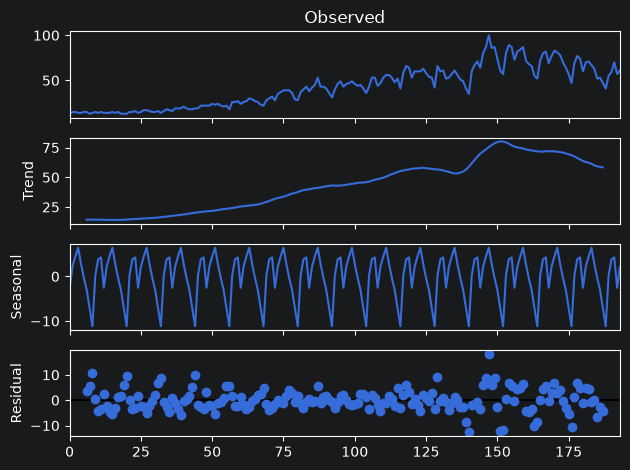

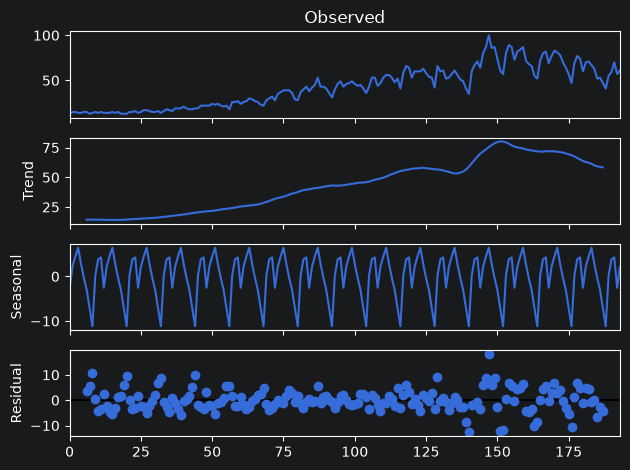

In [9]:
dec.plot()

The residual component is larger at the beginning (2010-2015, when Python is not very popular) and near 2021, when its popularity jumps.

This can be explained by historical events.

Power of the seasonality / original time-series .

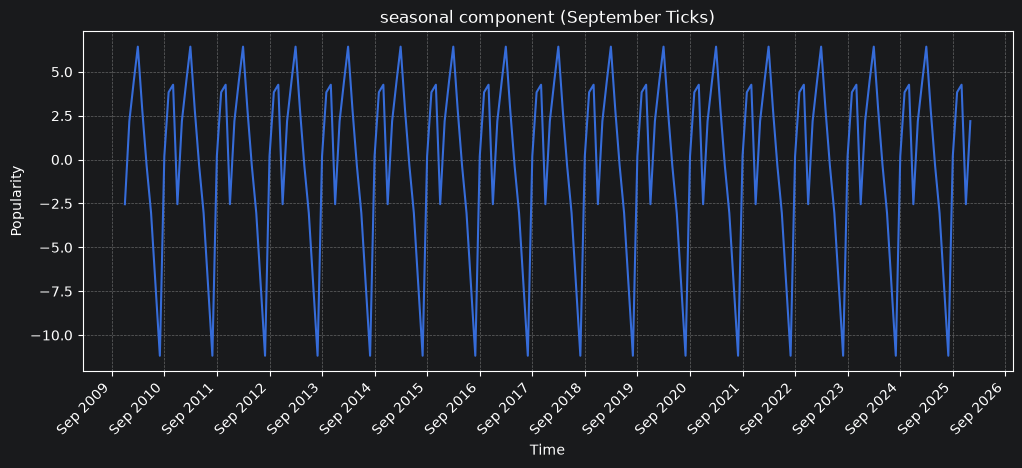

In [11]:
# plot the seasonality component
# dec.seasonal.plot() # -> 'numpy.ndarray' object has no attribute 'plot'

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df["Time"], dec.seasonal , label="seasonal component")

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=9))

# Format the tick labels, e.g. "Sep 2020" or "2020-09"
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Rotate and align date tick labels nicely
fig.autofmt_xdate(rotation=45)

ax.set_title("seasonal component (September Ticks)")
ax.set_xlabel("Time")
ax.set_ylabel("Popularity")
ax.grid(True, linestyle="--", alpha=0.5)



In [ ]:
# Compute power (quadratic mean) of the seasonality component
